In [208]:
%%capture
!pip install transformers accelerate bitsandbytes torch datasets

# COMET (MT evaluation)
!pip install "unbabel-comet>=2.0.0"

In [231]:
from transformers import AutoModelForCausalLM, AutoTokenizer, pipeline, BitsAndBytesConfig
from transformers import pipeline, AutoModelForSeq2SeqLM, AutoTokenizer, Trainer, TrainingArguments, AutoConfig
from transformers import AutoProcessor, SeamlessM4Tv2Model, AutoTokenizer
from comet import download_model, load_from_checkpoint
import torch
from tqdm import tqdm
import json

from datasets import load_dataset
from huggingface_hub import notebook_login
from huggingface_hub import logging as hf_logging
import numpy as np
import re

import matplotlib.pyplot as plt

In [31]:
torch.manual_seed(42)
np.random.seed(42)

In [27]:
hf_logging.set_verbosity_error()

In [5]:
MODEL_ID = "Qwen/Qwen2.5-14B-Instruct"

In [12]:
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=torch.float16
)

In [13]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    device_map="auto",
    quantization_config= bnb_config,
    torch_dtype="auto",
    use_safetensors=True
)

Fetching 8 files:   0%|          | 0/8 [00:00<?, ?it/s]

model-00001-of-00008.safetensors:   0%|          | 0.00/3.89G [00:00<?, ?B/s]

model-00007-of-00008.safetensors:   0%|          | 0.00/4.00G [00:00<?, ?B/s]

model-00004-of-00008.safetensors:   0%|          | 0.00/4.00G [00:00<?, ?B/s]

model-00002-of-00008.safetensors:   0%|          | 0.00/4.00G [00:00<?, ?B/s]

model-00006-of-00008.safetensors:   0%|          | 0.00/4.00G [00:00<?, ?B/s]

model-00003-of-00008.safetensors:   0%|          | 0.00/4.00G [00:00<?, ?B/s]

model-00005-of-00008.safetensors:   0%|          | 0.00/3.98G [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/8 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

In [14]:
generator = pipeline(
    "text-generation",
    model=model,
    tokenizer=tokenizer,
    device_map="auto"
)

Device set to use cuda:0


In [28]:
DATASET_ID = "umairhassan02/coco-captions-subset-59k-translated-final"
dataset = load_dataset(DATASET_ID)

README.md:   0%|          | 0.00/892 [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/31 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/31 [00:00<?, ?it/s]

data/train-00000-of-00031.parquet:   0%|          | 0.00/104M [00:00<?, ?B/s]

data/train-00001-of-00031.parquet:   0%|          | 0.00/103M [00:00<?, ?B/s]

...

data/validation-00001-of-00003.parquet:   0%|          | 0.00/91.9M [00:00<?, ?B/s]

data/validation-00002-of-00003.parquet:   0%|          | 0.00/90.8M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/292907 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/25014 [00:00<?, ? examples/s]

Loading dataset shards:   0%|          | 0/31 [00:00<?, ?it/s]

In [68]:
def build_prompt_single(item):
    """
    Craft a structured prompt for a single caption refinement.
    """
    text = "You are a professional Urdu linguist.\n"
    text += "For this caption:\n"
    text += "- Improve both Urdu translations (A = Reference, B = MT).\n"
    text += "- Strictly preserve meaning, do not add/remove details.\n"
    text += "- Make the Urdu fluent, natural, and aligned with the English caption.\n"
    text += "- Return ONLY valid JSON, no explanations, no commentary, no markdown, no extra text.\n"
    text += "Format must be exactly:"
    text += "id should be double quoted while A and B are also double quoted"
    text += "{'id': {A: '...', B: '...'}}\n\n"
    text += "please do not include anything else in the output"

    text += f"ID: {item['ID']}\n"
    text += f"English: {item['english']}\n"
    text += f"Reference Urdu (A): {item['ref']}\n"
    text += f"MT Urdu (B): {item['mt']}\n"

    return text

In [108]:
def extract_json(text):
    # Match blocks that contain at least one double-quote → more likely valid JSON
    matches = re.findall(r"\{[^{}]*\"[^{}]*\}", text, re.DOTALL)

    for block in reversed(matches):
        try:
            parsed = json.loads(block)
            if all(k in parsed for k in ["id", "A", "B"]):
                return parsed
        except Exception:
            continue
    return None

In [124]:
def refine_captions_single(caption_list, generator, save_path="refined.jsonl", batch_size=10):
    """
    caption_list: list of dicts with keys {ID, english, ref, mt}
    generator: Hugging Face pipeline for text-generation
    save_path: where to checkpoint results (JSONL)

    Returns dict {ID: {"A": improved_A, "B": improved_B}}
    """
    results = {}
    n = len(caption_list)
    with open(save_path, "a", encoding="utf-8") as f:
        for idx in tqdm(range(0, n, batch_size)):
            to= min(idx + batch_size, n)
            prompts = [build_prompt_single(item) for item in caption_list[idx:to]]

            output = generator(
                prompts,
                max_new_tokens=256,
                temperature=0.2,
                top_p=0.9,
                do_sample=True
            )

            for sub_idx, response in enumerate(output):
                out = response[0]['generated_text']
                item = caption_list[idx + sub_idx]
                
                # Extract only the JSON-like part
                try:
                    parsed_item = extract_json(out)
                    if parsed_item is None:
                        Exception("Corrupted model JSON format")
                    assert(str(parsed_item['id']) == str(item['ID']))
                    results[item["ID"]] = parsed_item
                    # Save checkpoint (1 line per caption)
                    f.write(json.dumps({item["ID"]: parsed_item}, ensure_ascii=False) + "\n")
                        
                except Exception as e:
                    print(f"⚠️ Parsing failed for itemId={item['ID']}: {e}")
                    results[item["ID"]] = None
            del output

    return results

In [32]:
low_scoring_captions = {}
for split in ['validation', 'train']:
  final_scores = dataset[split]['final_score']
  mask = np.array(final_scores) < 0.7
  low_indices = np.where(mask)[0]

  captions_hash = []
  for i in low_indices:
    idx = int(i)
    english = dataset[split]['caption'][idx]
    ref = dataset[split]['references'][idx]
    mt = dataset[split]['translated_captions'][idx]

    captions_hash.append({
        "ID": idx,
        "english": english,
        "ref": ref,
        "mt": mt
    })

  low_scoring_captions[split] = captions_hash

In [37]:
len(low_scoring_captions['train']) + len(low_scoring_captions['validation'])

3572

In [23]:
print(json.dumps(results, ensure_ascii=False, indent=2))

{
  "001": {
    "A": "ایک آدمی سبز کیلے کے تنے پر کھڑا ہے۔",
    "B": "ئی سبز کیلے کے چھڑے پر ایک مرد کھڑا ہے."
  },
  "002": {
    "A": "ایک بچہ سرخ گیند سے کھیل رہا ہے۔",
    "B": "بچہ ایک لال گیند کے ساتھ کھیل رہا ہے."
  }
}


In [135]:
refined_captions_train = {}
refined_captions_train = refine_captions_single(low_scoring_captions['train'], generator, "caption_refinemenets_train.jsonl")

 10% 33/330 [28:15<4:46:34, 57.89s/it]

⚠️ Parsing failed for itemId=29802: 'NoneType' object is not subscriptable


 12% 39/330 [33:59<4:48:41, 59.52s/it]

⚠️ Parsing failed for itemId=35579: 'NoneType' object is not subscriptable


 15% 50/330 [43:35<4:00:39, 51.57s/it]

...

 98% 325/330 [4:37:45<04:04, 48.81s/it]

⚠️ Parsing failed for itemId=285843: 'NoneType' object is not subscriptable


 99% 327/330 [4:39:40<02:42, 54.32s/it]

⚠️ Parsing failed for itemId=288182: 'NoneType' object is not subscriptable


100% 330/330 [4:41:54<00:00, 51.26s/it]


In [136]:
refined_captions_validation = {}
refined_captions_validation = refine_captions_single(low_scoring_captions['validation'], generator, "caption_refinemenets_validation.jsonl")

 57% 16/28 [12:49<09:47, 48.93s/it]

⚠️ Parsing failed for itemId=13769: 'NoneType' object is not subscriptable


 64% 18/28 [14:44<09:00, 54.07s/it]

⚠️ Parsing failed for itemId=16146: 'NoneType' object is not subscriptable
⚠️ Parsing failed for itemId=16167: 'NoneType' object is not subscriptable


 96% 27/28 [22:10<00:49, 49.12s/it]

⚠️ Parsing failed for itemId=23923: 'NoneType' object is not subscriptable


100% 28/28 [22:17<00:00, 47.78s/it]


In [143]:
dataset['validation'][16167]

{'image_id': 568290,
 'image': <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=640x427>,
 'caption': 'A bus driving down a road by some tall trees and buildings.',
 'translated_captions': 'ایک بس کچھ اونچے درختوں اور عمارتوں کی طرف سے ایک سڑک نیچے ڈرائیونگ.',
 'comet_flag': True,
 'comet_score': 0.6140961647033691,
 'bert_score': 0.974526584148407,
 'bert_flag': False,
 'back_translation': 'Just driving down a road by some tall trees and buildings.',
 'clip_score': 0.29222042123371456,
 'clip_flag': True,
 'final_score': 0.6938931837874535,
 'references': 'ایک بس کچھ اونچے درختوں اور عمارتوں کی طرف سے ایک سڑک کے نیچے ڈرائیونگ.'}

In [195]:
failed_ids = [
    29802, 35579, 44086, 47901, 76545, 87076, 101604, 110259, 113165,
    118420, 120815, 126065, 131107, 131919, 138954, 162102, 173393, 177388,
    180931, 186943, 189984, 192333, 194924, 202013, 209642, 211068, 212713,
    213449, 215143, 216632, 218011, 220253, 220763, 221313, 224248, 230136,
    232943, 237133, 237818, 239370, 240563, 247435, 252287, 254513, 260445,
    260889, 263822, 268033, 269386, 270934, 271034, 271402, 275363, 285281,
    285843, 288182
]

failed_validation_ids = [
    13769, 16146, 16167, 23923
]

In [196]:
validation_payload = {}
for _id in failed_validation_ids:
    validation_payload[_id] = {
        "eng": dataset['train'][_id]['caption'],
        "ref": dataset['train'][_id]['references'],
        "mt": dataset['train'][_id]['translated_captions']
    }

In [197]:
validation_payload

{13769: {'eng': 'A woman looking a motorcycles with balloons lined up on a street',
  'ref': 'ایک عورت ایک سڑک پر بالون کے ساتھ موٹر سائیکلوں کی تلاش میں',
  'mt': 'ایک عورت ایک سڑک پر قطار میں بیلون کے ساتھ موٹر سائیکلوں کو دیکھ رہا ہے'},
 16146: {'eng': 'A woman sitting on a bench with cars behind her.',
  'ref': 'ایک عورت جو ایک بینچ پر بیٹھی ہے اور اس کے پیچھے کاریں ہیں۔',
  'mt': 'ایک عورت ایک بینچ پر بیٹھی ہے جس کے پیچھے کاریں ہیں۔'},
 16167: {'eng': 'A dog herding sheep in an outside contest.',
  'ref': 'ایک کتا جو باہر کے مقابلے میں بھیڑوں کی دیکھ بھال کرتا ہے۔',
  'mt': 'ایک کتا باہر کے مقابلے میں بھیڑوں کو چرانے والا۔'},
 23923: {'eng': 'A group of people mill about on a beach with palm trees.',
  'ref': 'لوگوں کا ایک گروپ کھجور کے درختوں کے ساتھ ساحل پر گھومتا ہے.',
  'mt': 'کھجور کے درختوں کے ساتھ ایک ساحل سمندر پر لوگوں کا ایک گروپ مل کے بارے میں.'}}

In [283]:
for caption in low_scoring_captions['train']:
    improved_captions = refined_captions_train[caption['ID']]
    if improved_captions:
        caption['refined_mt'] = improved_captions['A']
        caption['refined_ref'] = improved_captions['B']

In [185]:
def read_json_objects(file_path):
    # Load JSON file
    with open(file_path, "r", encoding="utf-8") as f:
        data = json.load(f)
    
    # Iterate over objects
    for obj_id, obj_content in data.items():
        eng = obj_content.get("eng", "")
        ref = obj_content.get("ref", "")
        mt = obj_content.get("mt", "")

    return data

In [284]:
data = read_json_objects("cr.json")

In [286]:
for caption in low_scoring_captions['train']:
    key = str(caption['ID'])
    if key in data:
        manual_improved_caption = data[key]
        if manual_improved_caption:
            caption['refined_mt'] = manual_improved_caption['mt']
            caption['refined_ref'] = manual_improved_caption['ref']

In [287]:
# Validation split imporvements
for caption in low_scoring_captions['validation']:
    improved_captions = refined_captions_validation[caption['ID']]
    if improved_captions:
        caption['refined_mt'] = improved_captions['A']
        caption['refined_ref'] = improved_captions['B']

In [288]:
validation_data = read_json_objects("valid_cr.json")

In [289]:
for caption in low_scoring_captions['validation']:
    key = str(caption['ID'])
    if key in validation_data:
        manual_improved_caption = validation_data[key]
        if manual_improved_caption:
            caption['refined_mt'] = manual_improved_caption['mt']
            caption['refined_ref'] = manual_improved_caption['ref']

In [290]:
cnt = {}
for split in ['validation', 'train']:
    c = 0
    for caption in low_scoring_captions[split]:
        if 'refined_mt' not in caption.keys():
            c = c + 1
        cnt[split] = c

In [291]:
assert(list(cnt.values()) == [0,0])

In [224]:
del model
del generator

NameError: name 'model' is not defined

In [227]:
import gc
gc.collect()
torch.cuda.empty_cache()

## Re-score improved captions

In [212]:
notebook_login()

In [214]:
!git config --global credential.helper store

In [235]:
dataset['validation'][1]

{'image_id': 397133,
 'image': <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=640x427>,
 'caption': 'Man in apron standing on front of oven with pans and bakeware',
 'translated_captions': 'فرن کے سامنے کھڑے فرن اور بیک ویئر کے ساتھ فرن کے سامنے کھڑا ہے',
 'comet_flag': True,
 'comet_score': 0.4664641320705414,
 'bert_score': 0.8836208581924438,
 'bert_flag': False,
 'back_translation': 'Standing in front of the furnace with the furnace and bakeware standing in front of the furnace',
 'clip_score': 0.6091787739538596,
 'clip_flag': True,
 'final_score': 0.661869750895966,
 'references': 'فرن کے سامنے کھڑے فرن اور بیکنگ کے ساتھ آدمی'}

In [292]:
lookup = {}
lookup['train'] = {item["ID"]: item for item in low_scoring_captions['train']}
lookup['validation'] = {item["ID"]: item for item in low_scoring_captions['validation']}
def update_fn(example, idx, split):
    if idx in lookup[split]:
        example["translated_captions"] = lookup[split][idx]["refined_mt"]
        example["references"] = lookup[split][idx]["refined_ref"]
    return example

In [293]:
import copy
SPLITS = ['train', 'validation']
dp = copy.deepcopy(dataset)
for split in SPLITS:
    dp[split] = dp[split].map(lambda ex, i: update_fn(ex, i, split), with_indices=True)

Map:   0%|          | 0/292907 [00:00<?, ? examples/s]

Map:   0%|          | 0/25014 [00:00<?, ? examples/s]

In [294]:
dataset['validation'][1]

{'image_id': 397133,
 'image': <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=640x427>,
 'caption': 'Man in apron standing on front of oven with pans and bakeware',
 'translated_captions': 'فرن کے سامنے کھڑے فرن اور بیک ویئر کے ساتھ فرن کے سامنے کھڑا ہے',
 'comet_flag': True,
 'comet_score': 0.4664641320705414,
 'bert_score': 0.8836208581924438,
 'bert_flag': False,
 'back_translation': 'Standing in front of the furnace with the furnace and bakeware standing in front of the furnace',
 'clip_score': 0.6091787739538596,
 'clip_flag': True,
 'final_score': 0.661869750895966,
 'references': 'فرن کے سامنے کھڑے فرن اور بیکنگ کے ساتھ آدمی'}

In [295]:
dp['validation'][1]

{'image_id': 397133,
 'image': <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=640x427>,
 'caption': 'Man in apron standing on front of oven with pans and bakeware',
 'translated_captions': 'فرن کے سامنے کھڑے آدمی جس کے پاس فرن اور بیکنگ کے ابزار ہیں',
 'comet_flag': True,
 'comet_score': 0.4664641320705414,
 'bert_score': 0.8836208581924438,
 'bert_flag': False,
 'back_translation': 'Standing in front of the furnace with the furnace and bakeware standing in front of the furnace',
 'clip_score': 0.6091787739538596,
 'clip_flag': True,
 'final_score': 0.661869750895966,
 'references': 'فرن کے سامنے کھڑا ہے، جس کے پاس فرن اور بیکنگ کے ابزار ہیں'}

In [298]:
low_scoring_captions['train'][20:40]

[{'ID': 1975,
  'english': 'a man holding a bat ready to kick a tennis',
  'ref': 'ایک آدمی ایک ٹینس کی گیند کو لات مارنے کے لئے تیار ایک بیٹ پکڑ',
  'mt': 'ایک آدمی ایک بیٹ پکڑنے ایک ٹینس ایک ٹوکری کو لات مارنے کے لئے تیار ایک آدمی',
  'refined_mt': 'ایک آدمی ایک بیٹ پکھا رہے ہوں جو ایک ٹینس کی گیند کو لات مارنے کے لئے تیار ہے',
  'refined_ref': 'ایک آدمی ایک بیٹ پکھا رہے ہوں جو ایک ٹینس کی گیند کو لات مارنے کے لئے تیار ہے'},
 {'ID': 2134,
  'english': 'A clock sitting next to a pier, with a group of people below it.',
  'ref': 'ایک گھڑی جو ایک پے کے پاس بیٹھی ہے، اس کے نیچے لوگوں کے ایک گروپ کے ساتھ.',
  'mt': 'ایک گھڑی ایک پائل کے ساتھ بیٹھا ہے، اس کے نیچے لوگوں کے ایک گروپ کے ساتھ.',
  'refined_mt': 'ایک گھڑی جو ایک پیر کے پاس ہے، اس کے نیچے لوگوں کا ایک گروپ ہے۔',
  'refined_ref': 'ایک گھڑی جو ایک پیر کے ساتھ ہے، اس کے نیچے لوگوں کا ایک گروپ ہے۔'},
 {'ID': 2164,
  'english': 'a couple of glass vases with a flower growing out of it ',
  'ref': 'ایک گلاس کے جوڑے کے گلدستے جس میں سے 

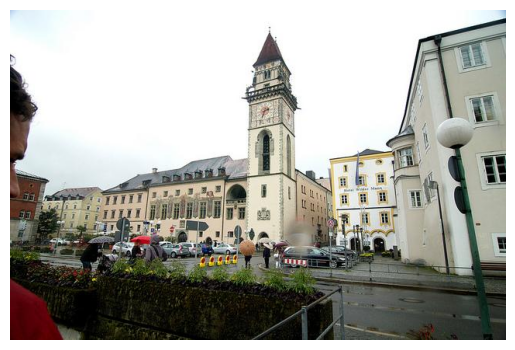

original machine transalation: اس میں کاروں کے ساتھ ایک شہر پارکنگ بہت سے کی ایک تصویر
refined machine transalation: ایک شہر کی پارکنگ کی تصویر جس میں کاریں ہیں۔


In [308]:
plt.imshow(dataset['train'][4221]['image'])
plt.axis("off")
plt.show()

print(f"original machine transalation: {dataset['train'][4221]['translated_captions']}")
print(f"refined machine transalation: {dp['train'][4221]['translated_captions']}")

In [309]:
REFINED_DATASET_ID = "umairhassan02/coco-captions-subset-refined"
dp.push_to_hub(REFINED_DATASET_ID)

Uploading the dataset shards:   0%|          | 0/31 [00:00<?, ? shards/s]

Map:   0%|          | 0/9449 [00:00<?, ? examples/s]

Creating parquet from Arrow format:   0%|          | 0/95 [00:00<?, ?ba/s]

Processing Files (0 / 0)                : |          |  0.00B /  0.00B            

New Data Upload                         : |          |  0.00B /  0.00B            

...

Creating parquet from Arrow format:   0%|          | 0/84 [00:00<?, ?ba/s]

Processing Files (0 / 0)                : |          |  0.00B /  0.00B            

New Data Upload                         : |          |  0.00B /  0.00B            

                                        :  31%|###       | 27.9MB / 90.8MB            

CommitInfo(commit_url='https://huggingface.co/datasets/umairhassan02/coco-captions-subset-refined/commit/a641297390a7fba2fb04711761fba9565a4a5715', commit_message='Upload dataset', commit_description='', oid='a641297390a7fba2fb04711761fba9565a4a5715', pr_url=None, repo_url=RepoUrl('https://huggingface.co/datasets/umairhassan02/coco-captions-subset-refined', endpoint='https://huggingface.co', repo_type='dataset', repo_id='umairhassan02/coco-captions-subset-refined'), pr_revision=None, pr_num=None)